# Deutsch–Jozsa

In [1]:
import pennylane as qml
import numpy as np
import matplotlib.pyplot as plt

In [2]:
n_qubits = 3
input_wires = list(range(n_qubits))
output_wire = n_qubits
device = qml.device("default.qubit", wires=n_qubits + 1)

In [3]:
def constant_oracle():
    qml.Identity(wires=output_wire)


def balanced_oracle():
    for wire in input_wires:
        qml.CNOT(wires=[wire, output_wire])

In [4]:
@qml.qnode(device)
def deutsch_jozsa(oracle):
    qml.PauliX(wires=output_wire)

    for wire in input_wires + [output_wire]:
        qml.Hadamard(wires=wire)

    oracle()

    for wire in input_wires:
        qml.Hadamard(wires=wire)

    return qml.probs(wires=input_wires)

## Entrada constante: f(x) = 0

In [5]:
constant_probabilities = deutsch_jozsa(constant_oracle)
constant_state = format(int(np.argmax(constant_probabilities)), f"0{n_qubits}b")

print("Resultado:", "constante" if np.isclose(constant_probabilities[0], 1) else "balanceada")
print("Estado medido:", constant_state)
print(qml.draw(deutsch_jozsa)(constant_oracle))

Resultado: constante
Estado medido: 000
0: ──H────╭I──H─┤ ╭Probs
1: ──H────├I──H─┤ ├Probs
2: ──H────├I──H─┤ ╰Probs
3: ──X──H─╰I────┤       


## Entrada balanceada

In [6]:
balanced_probabilities = deutsch_jozsa(balanced_oracle)
balanced_state = format(int(np.argmax(balanced_probabilities)), f"0{n_qubits}b")

print("Resultado:", "constante" if np.isclose(balanced_probabilities[0], 1) else "balanceada")
print("Estado medido:", balanced_state)
print(qml.draw(deutsch_jozsa)(balanced_oracle))

Resultado: balanceada
Estado medido: 111
0: ──H────╭●──H───────┤ ╭Probs
1: ──H────│──╭●──H────┤ ├Probs
2: ──H────│──│──╭●──H─┤ ╰Probs
3: ──X──H─╰X─╰X─╰X────┤       


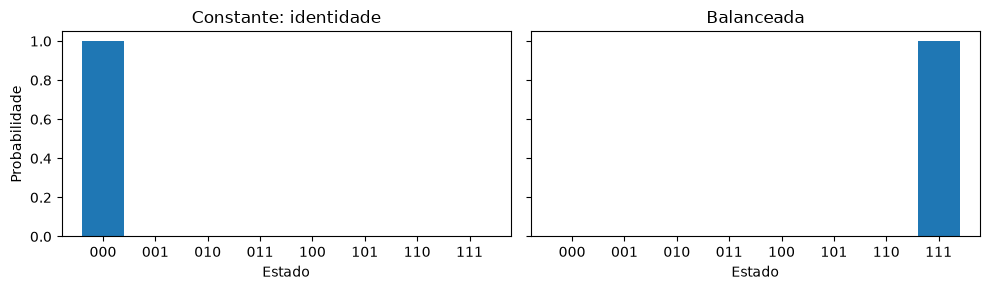

In [7]:
states = [format(index, f"0{n_qubits}b") for index in range(2 ** n_qubits)]
fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharey=True)

for axis, probabilities, title in zip(axes, [constant_probabilities, balanced_probabilities], ["Constante: identidade", "Balanceada"]):
    axis.bar(states, probabilities)
    axis.set(title=title, xlabel="Estado", ylim=(0, 1.05))

axes[0].set_ylabel("Probabilidade")
plt.tight_layout()
plt.show()